# Lumis 08: Final test evaluation (run once)

The frozen test set (972 images, every one human-checked) is used **exactly once**, on the final model, with the temperature and confidence thresholds fixed on the validation set. Nothing here may be tuned afterwards: these are the numbers the report and presentation quote.

1. Overall performance: accuracy, macro F1, sensitivity, specificity and F1 per class, with 95% bootstrap confidence intervals
2. Calibration on unseen data (RQ2): ECE before and after the validation temperature
3. The app's confidence bands on test data: how much Lumis answers, refers, and how accurate each band is. Includes the scabies rule: a scabies prediction is never shown as high confidence (validation precision for scabies was only 40%, and scabies needs a doctor's prescription anyway)
4. **Fairness by skin tone:** light (I-II) against darker (III-VI), plus V-VI on its own as an observation only

If results already exist, the notebook stops instead of overwriting them. CPU is fine (about 2 to 5 minutes).

## 1. Setup

In [1]:
RUN = None     # None = the latest EfficientNet-B0 run (the final model)
SEED = 42
B = 2000       # bootstrap resamples for confidence intervals
CAP_SCABIES = True   # app rule decided 2026-11-11 from validation evidence, before the test set was used:
                     # a scabies prediction is never shown as 'high'; at most 'moderate' (doctor's check advised)

from google.colab import drive
drive.mount('/content/drive')

import os, json, zipfile, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/Lumis'
LOCAL = '/content/dermnet'
OUT = f'{BASE}/exports/final_test'
if os.path.exists(f'{OUT}/metrics.json'):
    raise SystemExit(f'The test set was already evaluated: see {OUT}. It must only be used once.')
os.makedirs(OUT, exist_ok=True)
if not os.path.exists(LOCAL):
    with zipfile.ZipFile(f'{BASE}/data/dermnet.zip') as z:
        z.extractall(LOCAL)

runs = pd.read_csv(f'{BASE}/exports/runs_log.csv')
if RUN is None:
    RUN = runs[runs.backbone == 'efficientnetb0'].iloc[-1]['run']
info = runs[runs.run == RUN].iloc[-1]
cal = json.load(open(f'{BASE}/exports/runs/{RUN}/calibration.json'))
T, CLASSES, BANDS = cal['temperature'], cal['classes'], cal['bands']
ADJ = np.array(cal.get('logit_adjust', [0.0] * len(CLASSES)))   # prior adjustment from notebook 04b/04
K = len(CLASSES)

split = pd.read_csv(f'{BASE}/data/lumis_split_v2.csv')
test = split[split.split == 'test'].reset_index(drop=True)
tones = pd.read_csv(f'{BASE}/data/skin_tone_labels_round1.csv')[['path', 'tone']]
test = test.merge(tones, on='path', how='left')
print(f'Model {RUN} | T = {T} | bands: high from {BANDS["high_from"]}, refer below {BANDS["refer_below"]}')
print(len(test), 'test images;', test.tone.isna().sum(), 'without a skin-tone label')

Mounted at /content/drive
Model efficientnetb0_20261109_1427 | T = 1.3044 | bands: high from 0.74, refer below 0.52
972 test images; 0 without a skin-tone label


## 2. Predict on the test set

In [2]:
import tensorflow as tf
import keras

PREPROCESS = {'mobilenetv2': keras.applications.mobilenet_v2.preprocess_input,
              'efficientnetb0': keras.applications.efficientnet.preprocess_input,
              'resnet50': keras.applications.resnet50.preprocess_input}[info.backbone]
size = int(info.img_size)
model = keras.models.load_model(info.model_file)

def load(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.cast(tf.cast(tf.image.resize(img, (size, size)), tf.uint8), tf.float32)   # same as training
    return PREPROCESS(img)

ds = (tf.data.Dataset.from_tensor_slices([os.path.join(LOCAL, p) for p in test.path])
      .map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(32))
t0 = time.time()
logits = model.predict(ds, verbose=0)
print(f'Predicted {len(logits)} images in {time.time() - t0:.0f} s')
np.save(f'{OUT}/test_logits.npy', logits)

Predicted 972 images in 636 s


## 3. Metrics and helpers

In [3]:
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def ece(probs, y, bins=15):
    conf, correct = probs.max(1), probs.argmax(1) == y
    edges, total = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(total)

y = np.array([CLASSES.index(c) for c in test.lumis_class])
raw = softmax(logits + ADJ)
probs = softmax((logits + ADJ) / T)
pred, conf = probs.argmax(1), probs.max(1)
correct = pred == y
band = np.where(conf >= BANDS['high_from'], 'high', np.where(conf >= BANDS['refer_below'], 'moderate', 'refer'))
band_uncapped = band.copy()
if CAP_SCABIES:
    band = np.where((pred == CLASSES.index('scabies')) & (band == 'high'), 'moderate', band)

def summary(idx):
    yt, yp = y[idx], pred[idx]
    cm = confusion_matrix(yt, yp, labels=range(K))
    sens = [cm[i, i] / cm[i].sum() for i in range(K) if cm[i].sum() > 0]
    spec = []
    for i in range(K):
        fp, tp = cm[:, i].sum() - cm[i, i], cm[i, i]
        tn = cm.sum() - cm[i].sum() - fp
        if tn + fp > 0:
            spec.append(tn / (tn + fp))
    answered = band[idx] != 'refer'
    return {'accuracy': (yt == yp).mean(),
            'macro_f1': f1_score(yt, yp, labels=range(K), average='macro', zero_division=0),
            'macro_sensitivity': np.mean(sens), 'macro_specificity': np.mean(spec),
            'referred': 1 - answered.mean(),
            'accuracy_when_answering': (yt[answered] == yp[answered]).mean() if answered.any() else np.nan}

rng = np.random.default_rng(SEED)
def with_ci(idx):
    point = summary(idx)
    boots = [summary(idx[rng.integers(0, len(idx), len(idx))]) for _ in range(B)]
    return {k: (round(float(v), 4), [round(float(np.nanpercentile([b[k] for b in boots], q)), 4) for q in (2.5, 97.5)])
            for k, v in point.items()}

ALL = np.arange(len(y))

## 4. Overall test performance

accuracy                   0.655   95% CI 0.625 to 0.684
macro_f1                   0.653   95% CI 0.620 to 0.683
macro_sensitivity          0.661   95% CI 0.628 to 0.695
macro_specificity          0.910   95% CI 0.902 to 0.917
referred                   0.312   95% CI 0.283 to 0.342
accuracy_when_answering    0.761   95% CI 0.728 to 0.793


,n,sensitivity,specificity,precision,f1
class,,,,,
acne,128,0.766,0.938,0.653,0.705
eczema,297,0.704,0.864,0.694,0.699
psoriasis,255,0.576,0.911,0.697,0.631
scabies,72,0.639,0.968,0.613,0.626
tinea,220,0.623,0.870,0.583,0.602


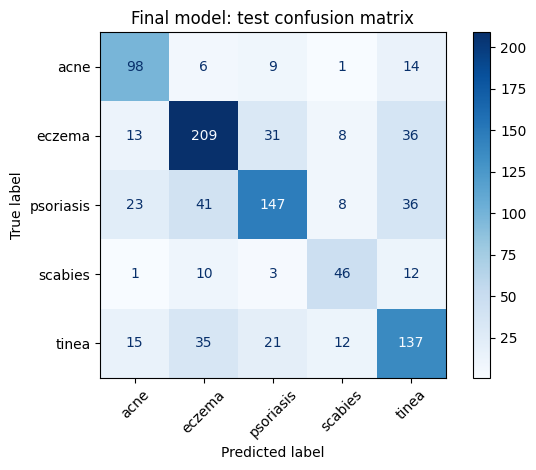

In [4]:
overall = with_ci(ALL)
for k, (v, ci) in overall.items():
    print(f'{k:26s} {v:.3f}   95% CI {ci[0]:.3f} to {ci[1]:.3f}')

cm = confusion_matrix(y, pred, labels=range(K))
rows = []
for i, c in enumerate(CLASSES):
    tp, fn, fp = cm[i, i], cm[i].sum() - cm[i, i], cm[:, i].sum() - cm[i, i]
    tn = cm.sum() - tp - fn - fp
    prec = tp / (tp + fp) if tp + fp else 0.0
    sens = tp / (tp + fn)
    rows.append({'class': c, 'n': int(cm[i].sum()), 'sensitivity': sens, 'specificity': tn / (tn + fp),
                 'precision': prec, 'f1': 2 * prec * sens / (prec + sens) if prec + sens else 0.0})
per_class = pd.DataFrame(rows).set_index('class').round(3)
display(per_class)
per_class.to_csv(f'{OUT}/per_class.csv')

ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap='Blues', xticks_rotation=45)
plt.title('Final model: test confusion matrix')
plt.tight_layout()
plt.savefig(f'{OUT}/confusion_matrix.png', dpi=120)
plt.show()

## 5. Calibration and confidence bands on unseen data (RQ2)

{'ece_raw': 0.065, 'ece_calibrated': 0.0313}


,share,accuracy,n
band,,,
high,0.323,0.892,314
moderate,0.365,0.645,355
refer,0.312,0.422,303


Scabies cap: {'moved_high_to_moderate': 28, 'accuracy_of_moved': 0.821}


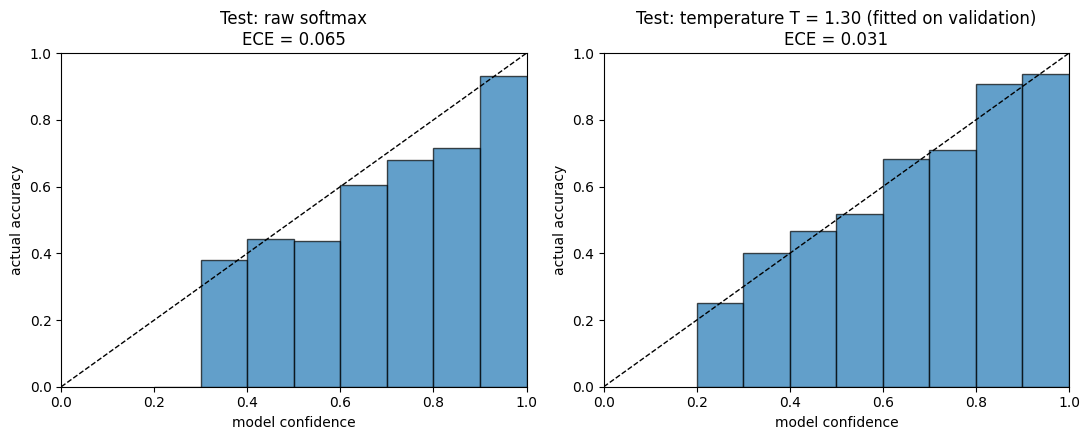

In [5]:
cal_test = {'ece_raw': round(ece(raw, y), 4), 'ece_calibrated': round(ece(probs, y), 4)}
print(cal_test)

band_rows = []
for b_name in ['high', 'moderate', 'refer']:
    m = band == b_name
    band_rows.append({'band': b_name, 'share': round(m.mean(), 3),
                      'accuracy': round(correct[m].mean(), 3) if m.any() else None, 'n': int(m.sum())})
bands_test = pd.DataFrame(band_rows).set_index('band')
display(bands_test)
bands_test.to_csv(f'{OUT}/bands.csv')
capped = (band_uncapped == 'high') & (band != 'high')
cap_info = {'moved_high_to_moderate': int(capped.sum()),
            'accuracy_of_moved': round(float(correct[capped].mean()), 3) if capped.any() else None}
print('Scabies cap:', cap_info)

def reliability(ax, p, title, bins=10):
    c, ok = p.max(1), p.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1)
    mids, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (c > lo) & (c <= hi)
        if m.any():
            mids.append((lo + hi) / 2); accs.append(ok[m].mean())
    ax.bar(mids, accs, width=1 / bins, edgecolor='black', alpha=0.7)
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('model confidence'); ax.set_ylabel('actual accuracy')
    ax.set_title(f'{title}\nECE = {ece(p, y):.3f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
reliability(ax[0], raw, 'Test: raw softmax')
reliability(ax[1], probs, f'Test: temperature T = {T:.2f} (fitted on validation)')
plt.tight_layout()
plt.savefig(f'{OUT}/reliability_test.png', dpi=120)
plt.show()

## 6. Fairness by skin tone

Light (I-II) is compared with darker skin (III-VI combined), because V-VI alone has too few images for reliable numbers; V-VI is shown separately as an observation only. Images marked "Can't tell" are excluded here.

The difference row is light minus darker, with a 95% bootstrap interval. If that interval includes zero, the test set is too small to show a difference either way, which must be reported as "not detected", not as "no bias".

Caution: the class mix differs between groups (for example, almost every acne image is light skin), so part of any gap can come from which conditions appear in each group, not skin tone alone. The per-class table below helps separate the two.

,n,accuracy,accuracy_ci,macro_sensitivity,macro_sensitivity_ci,referred,referred_ci,ece_calibrated,mean_confidence
group,,,,,,,,,
I-II (light),857,0.6558,"[0.6231, 0.6873]",0.6591,"[0.6228, 0.6948]",0.3046,"[0.2754, 0.3361]",0.0293,0.6515
III-VI (darker),101,0.6139,"[0.5248, 0.7129]",0.4606,"[0.3667, 0.6703]",0.3861,"[0.2871, 0.4851]",0.1315,0.5960
III-IV,84,0.6071,"[0.5, 0.7024]",0.4539,"[0.3569, 0.6705]",0.3929,"[0.2857, 0.5]",0.1521,0.5898
V-VI (observation only),17,0.6471,"[0.4118, 0.8824]",0.6333,"[0.3611, 0.8586]",0.3529,"[0.1176, 0.5882]",0.2812,0.6263


Light minus darker:
  accuracy           +0.042  (95% CI -0.057 to +0.140)  interval includes 0: no difference detectable at this sample size
  macro_sensitivity  +0.199  (95% CI -0.012 to +0.297)  interval includes 0: no difference detectable at this sample size
  referred           -0.082  (95% CI -0.183 to +0.013)  interval includes 0: no difference detectable at this sample size

Sensitivity per class and skin-tone group (count = images):


count          mean       
group        I-II III-VI   I-II III-VI
lumis_class                           
acne          127      1  0.772  0.000
eczema        258     38  0.702  0.711
psoriasis     221     28  0.570  0.571
scabies        59      7  0.627  0.429
tinea         192     27  0.625  0.593

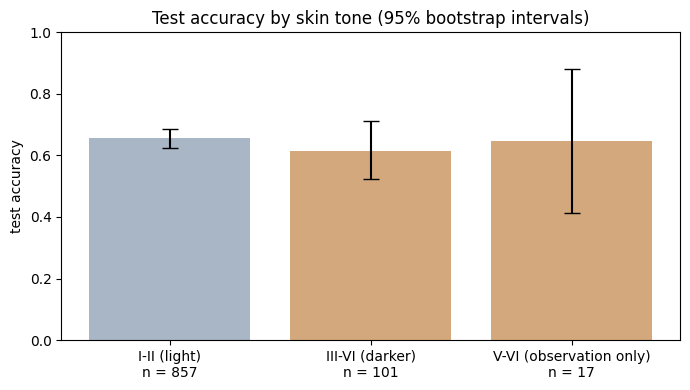

In [6]:
groups = {'I-II (light)': np.where(test.tone == 'I-II')[0],
          'III-VI (darker)': np.where(test.tone.isin(['III-IV', 'V-VI']))[0],
          'III-IV': np.where(test.tone == 'III-IV')[0],
          'V-VI (observation only)': np.where(test.tone == 'V-VI')[0]}

fair_rows = []
for g, idx in groups.items():
    s = with_ci(idx)
    fair_rows.append({'group': g, 'n': len(idx),
                      **{k: v for k, (v, _) in s.items()},
                      **{f'{k}_ci': ci for k, (_, ci) in s.items()},
                      'ece_calibrated': round(ece(probs[idx], y[idx]), 4) if len(idx) else None,
                      'mean_confidence': round(float(conf[idx].mean()), 4) if len(idx) else None})
fair = pd.DataFrame(fair_rows).set_index('group')

light, dark = groups['I-II (light)'], groups['III-VI (darker)']
diffs = {k: [] for k in ['accuracy', 'macro_sensitivity', 'referred']}
for _ in range(B):
    a = summary(light[rng.integers(0, len(light), len(light))])
    d = summary(dark[rng.integers(0, len(dark), len(dark))])
    for k in diffs:
        diffs[k].append(a[k] - d[k])
point_a, point_d = summary(light), summary(dark)
gap = {k: {'light_minus_darker': round(float(point_a[k] - point_d[k]), 4),
           'ci95': [round(float(np.percentile(v, q)), 4) for q in (2.5, 97.5)]} for k, v in diffs.items()}

show_cols = ['n', 'accuracy', 'accuracy_ci', 'macro_sensitivity', 'macro_sensitivity_ci', 'referred', 'referred_ci', 'ece_calibrated', 'mean_confidence']
display(fair[show_cols])
print('Light minus darker:')
for k, v in gap.items():
    verdict = 'interval excludes 0' if (v['ci95'][0] > 0 or v['ci95'][1] < 0) else 'interval includes 0: no difference detectable at this sample size'
    print(f"  {k:18s} {v['light_minus_darker']:+.3f}  (95% CI {v['ci95'][0]:+.3f} to {v['ci95'][1]:+.3f})  {verdict}")
fair.to_csv(f'{OUT}/fairness.csv')

per_class_tone = (test.assign(correct=correct, group=np.where(test.tone == 'I-II', 'I-II', np.where(test.tone.isin(['III-IV', 'V-VI']), 'III-VI', None)))
                  .dropna(subset=['group'])
                  .groupby(['lumis_class', 'group']).correct.agg(['count', 'mean']).unstack().round(3))
print('\nSensitivity per class and skin-tone group (count = images):')
display(per_class_tone)
per_class_tone.to_csv(f'{OUT}/fairness_per_class.csv')

fig, ax = plt.subplots(figsize=(7, 4))
names = ['I-II (light)', 'III-VI (darker)', 'V-VI (observation only)']
vals = [fair.loc[n, 'accuracy'] for n in names]
errs = np.array([[fair.loc[n, 'accuracy'] - fair.loc[n, 'accuracy_ci'][0], fair.loc[n, 'accuracy_ci'][1] - fair.loc[n, 'accuracy']] for n in names]).T
ax.bar(range(3), vals, yerr=errs, capsize=6, color=['#9ab', '#c96', '#c96'], alpha=0.85)
ax.set_xticks(range(3)); ax.set_xticklabels([f'{n}\nn = {fair.loc[n, "n"]}' for n in names])
ax.set_ylabel('test accuracy'); ax.set_ylim(0, 1)
ax.set_title('Test accuracy by skin tone (95% bootstrap intervals)')
plt.tight_layout()
plt.savefig(f'{OUT}/fairness_accuracy.png', dpi=120)
plt.show()

## 7. Save everything

In [7]:
pd.DataFrame({'path': test.path, 'true': test.lumis_class, 'pred': [CLASSES[i] for i in pred],
              'confidence': conf.round(4), 'band': band, 'correct': correct, 'tone': test.tone}
             ).to_csv(f'{OUT}/predictions.csv', index=False)
metrics = {'evaluated_at': time.strftime('%Y-%m-%d %H:%M'), 'run': RUN, 'n_test': int(len(y)),
           'temperature': T, 'prior_tau': cal.get('prior_tau', 0.0), 'bands': {'high_from': BANDS['high_from'], 'refer_below': BANDS['refer_below']},
           'scabies_cap': CAP_SCABIES, 'scabies_cap_effect': cap_info,
           'overall': overall, 'calibration': cal_test, 'fairness_gap': gap}
json.dump(metrics, open(f'{OUT}/metrics.json', 'w'), indent=1)
print('Saved to', OUT)
print(json.dumps(metrics, indent=1))

Saved to /content/drive/MyDrive/Lumis/exports/final_test
{
 "evaluated_at": "2026-11-10 19:31",
 "run": "efficientnetb0_20261109_1427",
 "n_test": 972,
 "temperature": 1.3044,
 "prior_tau": 0.75,
 "bands": {
  "high_from": 0.74,
  "refer_below": 0.52
 },
 "scabies_cap": true,
 "scabies_cap_effect": {
  "moved_high_to_moderate": 28,
  "accuracy_of_moved": 0.821
 },
 "overall": {
  "accuracy": [
   0.6553,
   [
    0.6255,
    0.6842
   ]
  ],
  "macro_f1": [
   0.6526,
   [
    0.6195,
    0.6834
   ]
  ],
  "macro_sensitivity": [
   0.6615,
   [
    0.6284,
    0.6945
   ]
  ],
  "macro_specificity": [
   0.9101,
   [
    0.9021,
    0.9175
   ]
  ],
  "referred": [
   0.3117,
   [
    0.2829,
    0.3416
   ]
  ],
  "accuracy_when_answering": [
   0.7608,
   [
    0.7277,
    0.7929
   ]
  ]
 },
 "calibration": {
  "ece_raw": 0.065,
  "ece_calibrated": 0.0313
 },
 "fairness_gap": {
  "accuracy": {
   "light_minus_darker": 0.0419,
   "ci95": [
    -0.0571,
    0.1398
   ]
  },
  "macro_